# EDA

# Cell 1: setup

In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df  = pd.read_csv("../data/processed_housing.csv")
raw = pd.read_csv("../data/raw_deduped_housing.csv")   # uncapped, for outlier analysis
df["PPSF"] = df["Price_per_SqFt_calc"]                 # price per sqft in Rs
df.shape

(250000, 44)

# Cell 2: Q1, price distribution

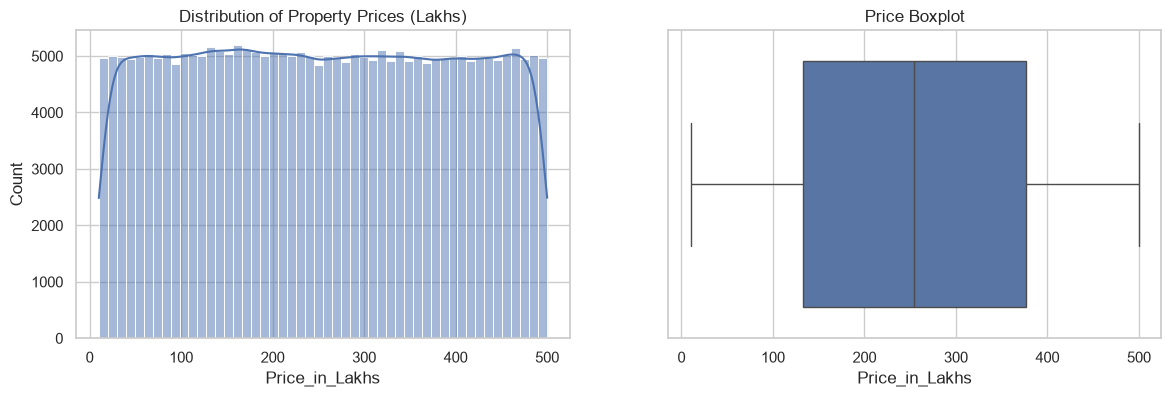

count    250000.000000
mean        254.586854
std         141.349921
min          10.000000
25%         132.550000
50%         253.870000
75%         376.880000
max         500.000000
Name: Price_in_Lakhs, dtype: float64
Skewness: 0.008


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Price_in_Lakhs"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Distribution of Property Prices (Lakhs)")
sns.boxplot(x=df["Price_in_Lakhs"], ax=ax[1])
ax[1].set_title("Price Boxplot")
plt.show()
print(df["Price_in_Lakhs"].describe())
print("Skewness:", df["Price_in_Lakhs"].skew().round(3))

# Cell 3: Q2, size distribution

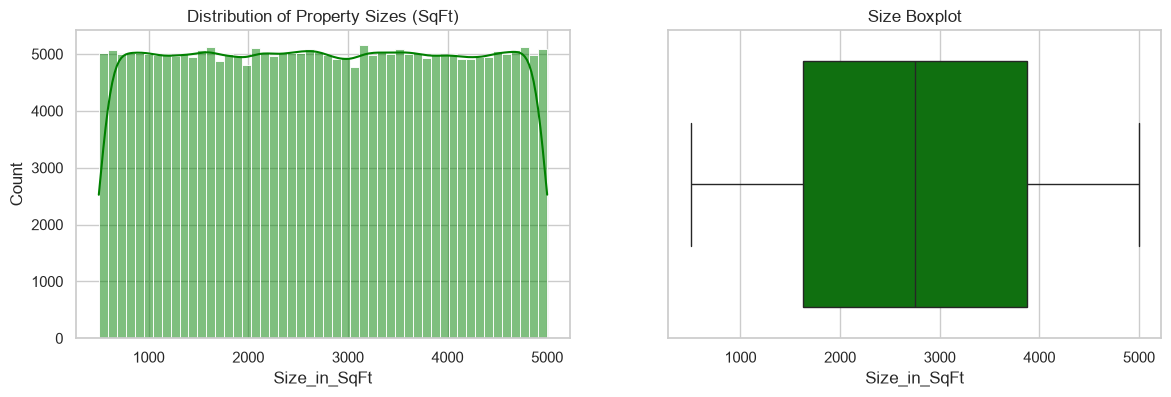

count    250000.000000
mean       2749.813216
std        1300.606954
min         500.000000
25%        1623.000000
50%        2747.000000
75%        3874.000000
max        5000.000000
Name: Size_in_SqFt, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Size_in_SqFt"], bins=50, kde=True, color="green", ax=ax[0])
ax[0].set_title("Distribution of Property Sizes (SqFt)")
sns.boxplot(x=df["Size_in_SqFt"],color="green", ax=ax[1])
ax[1].set_title("Size Boxplot")
plt.show()
print(df["Size_in_SqFt"].describe())


# Cell 4: Q3, price per sqft by property type

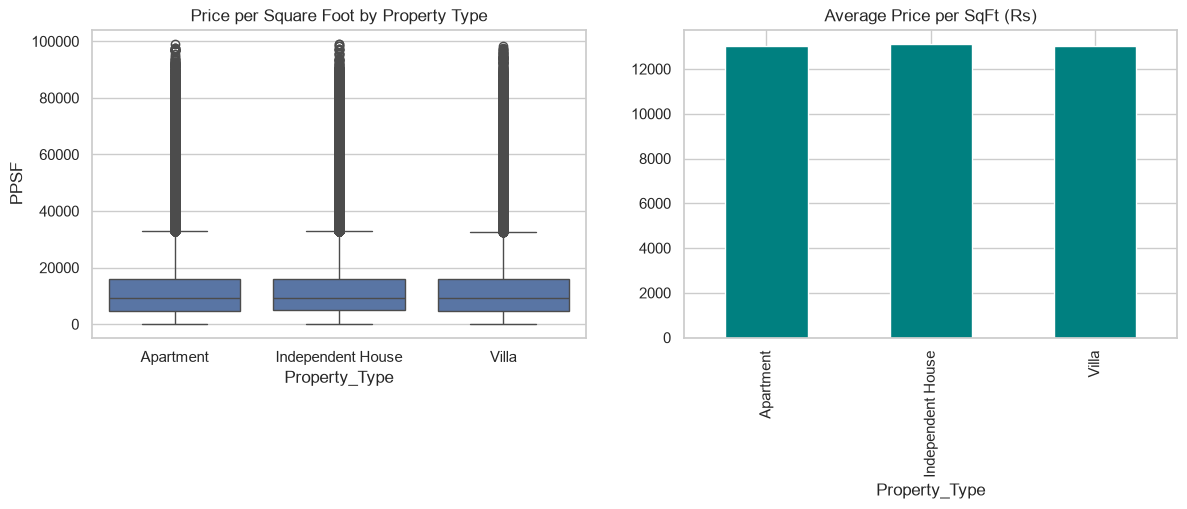

                      mean  median
Property_Type                     
Apartment          13047.0  9245.0
Independent House  13102.0  9305.0
Villa              13026.0  9190.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="Property_Type", y="PPSF", ax=ax[0])
ax[0].set_title("Price per Square Foot by Property Type")
df.groupby("Property_Type") ["PPSF"].mean().plot(kind="bar", ax=ax[1], color="teal")
ax[1].set_title("Average Price per SqFt (Rs)")
plt.show()
print(df.groupby("Property_Type")["PPSF"].agg(["mean","median"]).round(0))

# Cell 5: Q4, size vs price

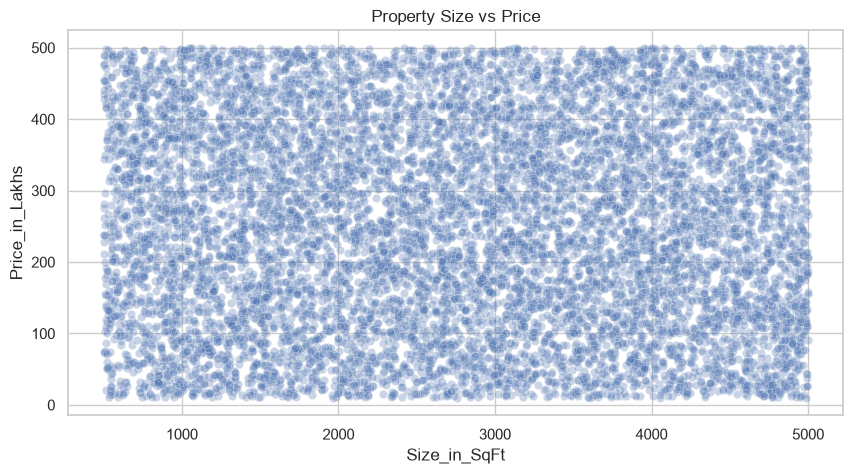

Correlation: -0.003


In [9]:
sample = df.sample(10000, random_state=42)
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3)
plt.title("Property Size vs Price")
plt.show()
print("Correlation:", df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]).round(3))

# Cell 6: Q5, outliers

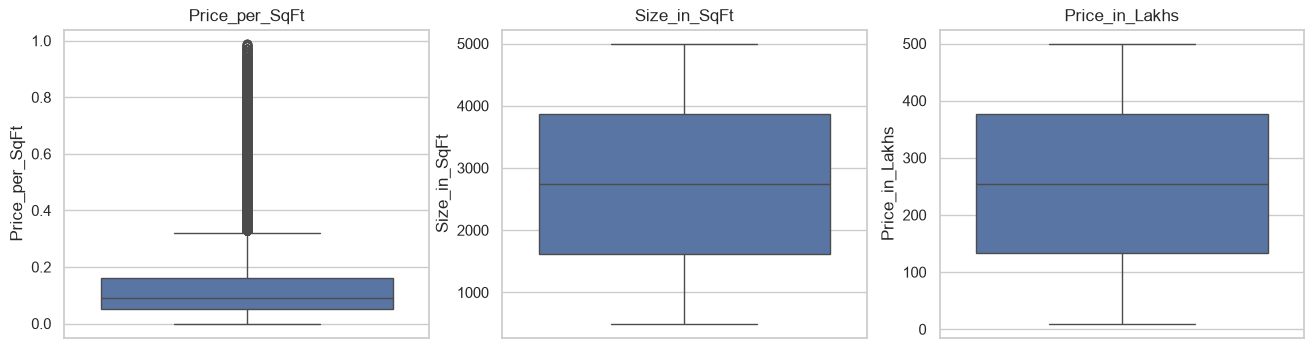

,feature,n_outliers,pct
0,Price_per_SqFt,20020,8.01
1,Size_in_SqFt,0,0.00
2,Price_in_Lakhs,0,0.00


In [10]:
cols = ["Price_per_SqFt", "Size_in_SqFt", "Price_in_Lakhs"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, cols):
    sns.boxplot(y=raw[c], ax=a); a.set_title(c)
plt.show()

rows = []
for c in cols:
    q1, q3 = raw[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((raw[c] < q1 - 1.5*iqr) | (raw[c] > q3 + 1.5*iqr)).sum()
    rows.append([c, n, round(n/len(raw)*100, 2)])
pd.DataFrame(rows, columns=["feature", "n_outliers", "pct"])

# Cell 7: Q6, average price per sqft by state

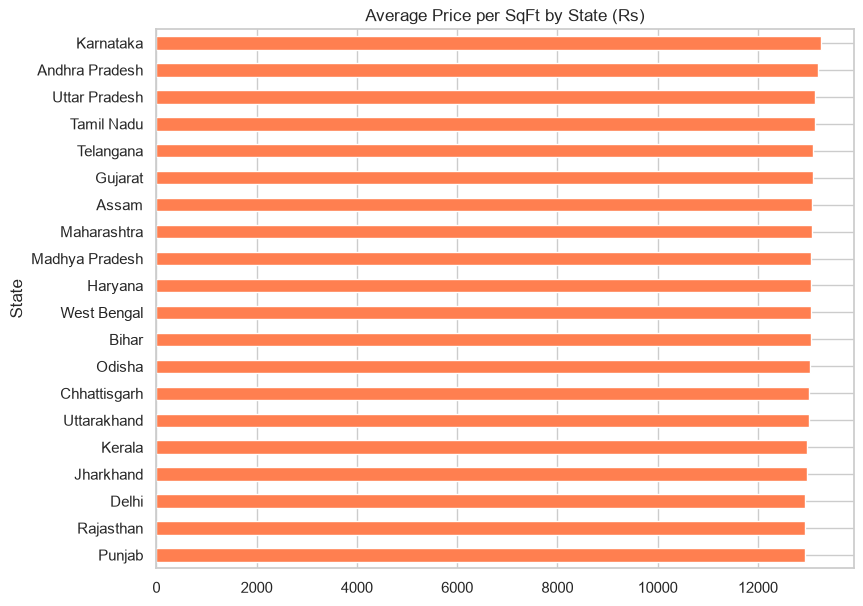

In [11]:
s = df.groupby("State")["PPSF"].mean().sort_values()
s.plot(kind="barh", figsize=(9, 7), color="coral")
plt.title("Average Price per SqFt by State (Rs)"); plt.show()

# Cell 8: Q7, average price by city

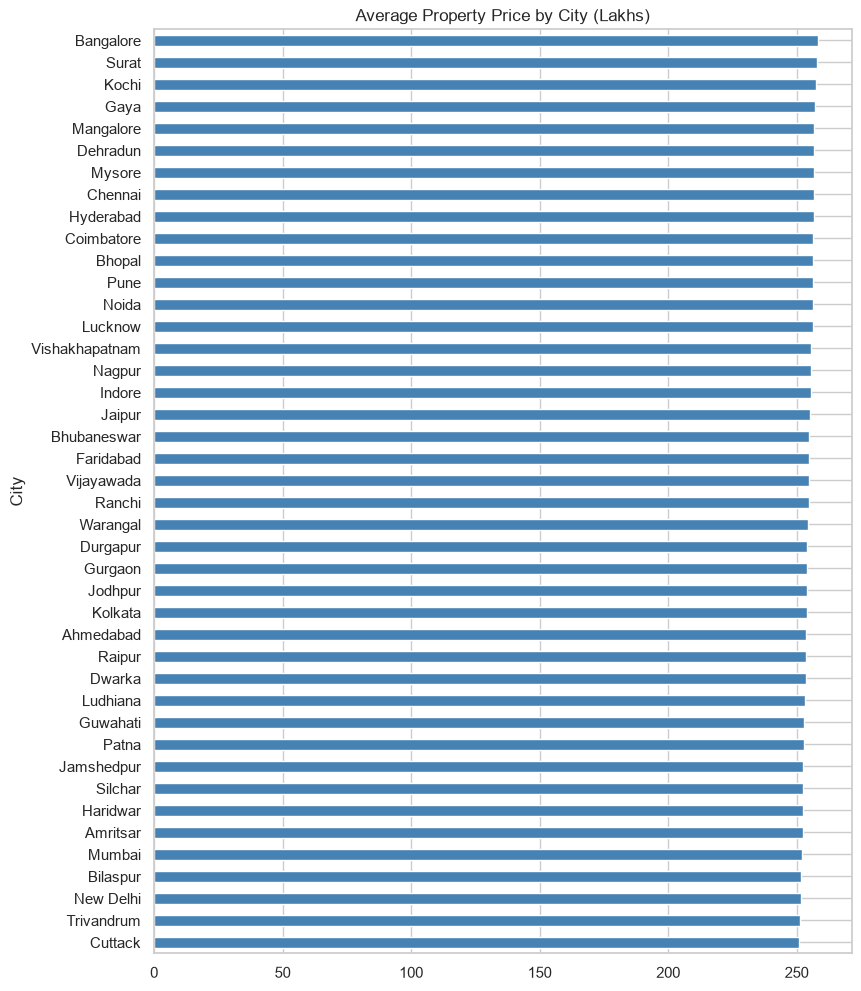

In [12]:
c = df.groupby("City")["Price_in_Lakhs"].mean().sort_values()
c.plot(kind="barh", figsize=(9, 12), color="steelblue")
plt.title("Average Property Price by City (Lakhs)"); plt.show()

# Cell 9: Q8, median age by locality

Oldest 10 localities:
 Locality
Locality_475    20.0
Locality_474    20.0
Locality_491    20.0
Locality_143    20.0
Locality_1      20.0
Locality_499    20.0
Locality_99     20.0
Locality_127    20.0
Locality_403    21.0
Locality_72     21.0
Name: Age_of_Property, dtype: float64 

Newest 10 localities:
 Locality
Locality_443    16.0
Locality_92     17.0
Locality_60     17.0
Locality_10     17.0
Locality_13     17.0
Locality_325    17.0
Locality_357    17.0
Locality_63     17.0
Locality_314    17.0
Locality_370    17.0
Name: Age_of_Property, dtype: float64


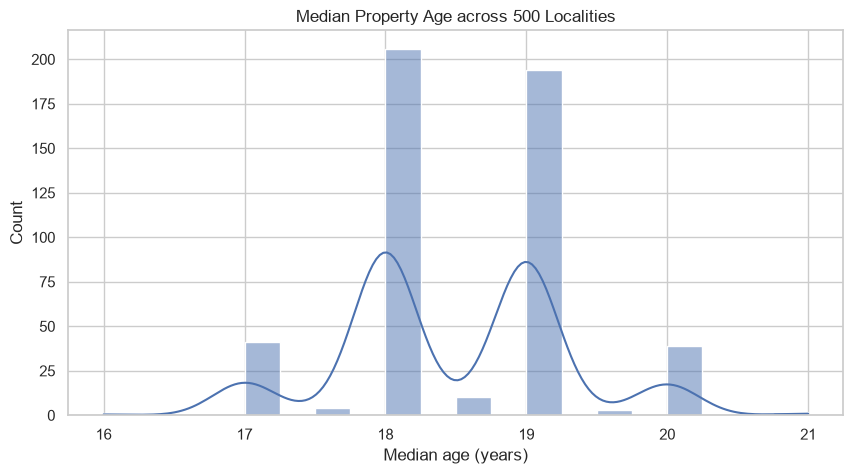

In [13]:
age = df.groupby("Locality")["Age_of_Property"].median().sort_values()
print("Oldest 10 localities:\n", age.tail(10), "\n\nNewest 10 localities:\n", age.head(10))
sns.histplot(age, bins=20, kde=True); plt.title("Median Property Age across 500 Localities")
plt.xlabel("Median age (years)"); plt.show()

# Cell 10: Q9, BHK distribution across cities

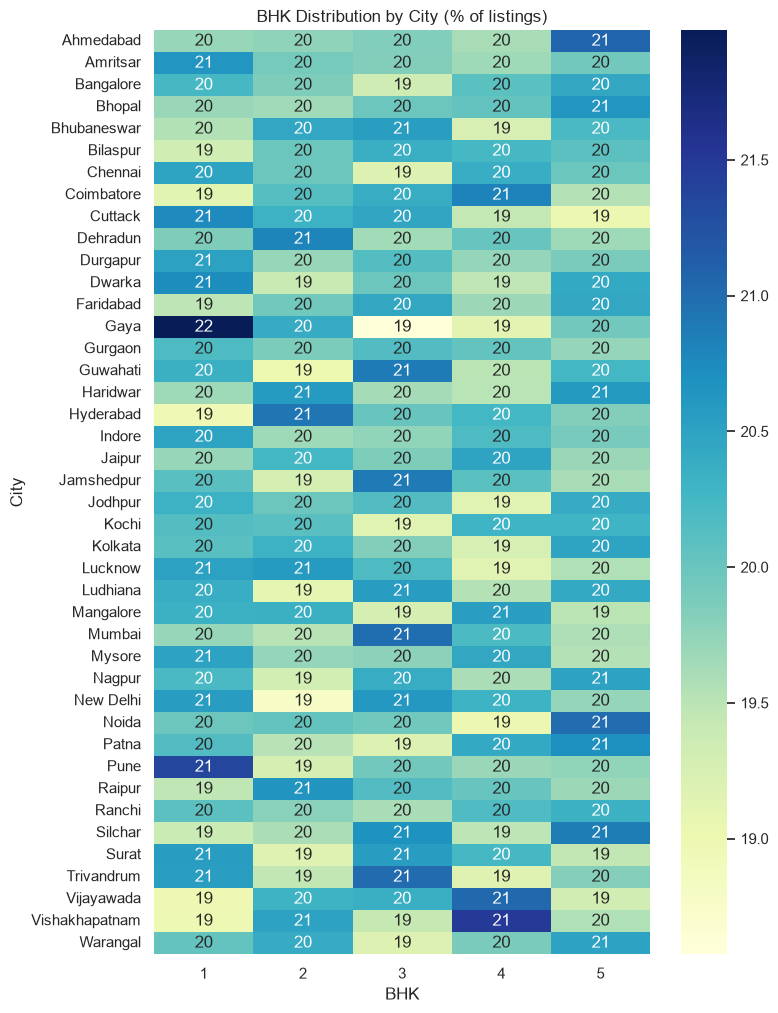

In [14]:
ct = pd.crosstab(df["City"], df["BHK"], normalize="index") * 100
plt.figure(figsize=(8, 12))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("BHK Distribution by City (% of listings)"); plt.show()

# Cell 11: Q10, price trends for the top 5 most expensive localities

# 

In [15]:
if "df" not in globals():
    import pandas as pd
    df = pd.read_csv("../data/processed_housing.csv")

top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).index.tolist()
print("Top 5 localities:", top5)

t = df[df["Locality"].isin(top5)].copy()
t["Build_Period"] = (t["Year_Built"] // 5) * 5          # group by 5-year periods
trend = t.groupby(["Build_Period", "Locality"])["Price_in_Lakhs"].mean().reset_index()
import plotly.express as px

fig = px.line(
    trend,
    x="Build_Period",
    y="Price_in_Lakhs",
    color="Locality",
    markers=True,
    title="Average Price by Construction Period, Top 5 Localities",
)
fig.show()

Top 5 localities: ['Locality_395', 'Locality_366', 'Locality_497', 'Locality_360', 'Locality_203']


# Cell 12: Q11, correlation matrix

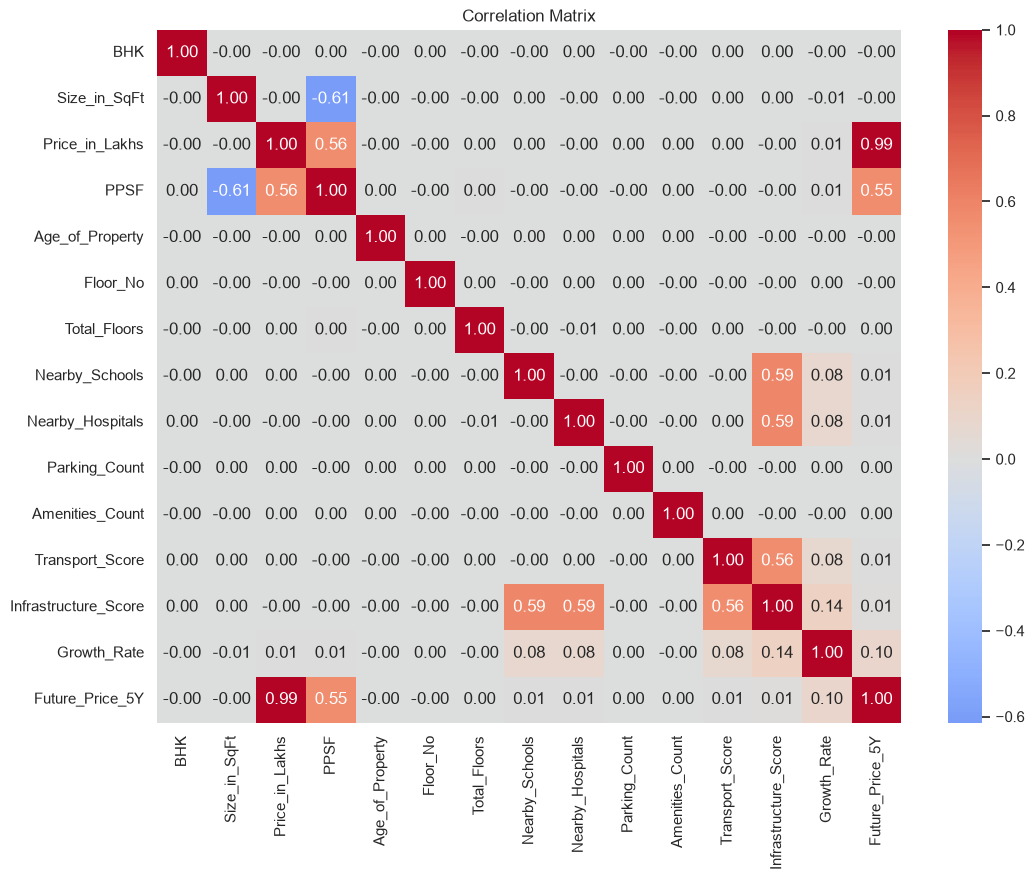

In [16]:
num = ["BHK","Size_in_SqFt","Price_in_Lakhs","PPSF","Age_of_Property","Floor_No","Total_Floors",
       "Nearby_Schools","Nearby_Hospitals","Parking_Count","Amenities_Count","Transport_Score",
       "Infrastructure_Score","Growth_Rate","Future_Price_5Y"]
plt.figure(figsize=(12, 9))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix"); plt.show()

# Cell 13: Q12 and Q13, schools and hospitals vs price per sqft

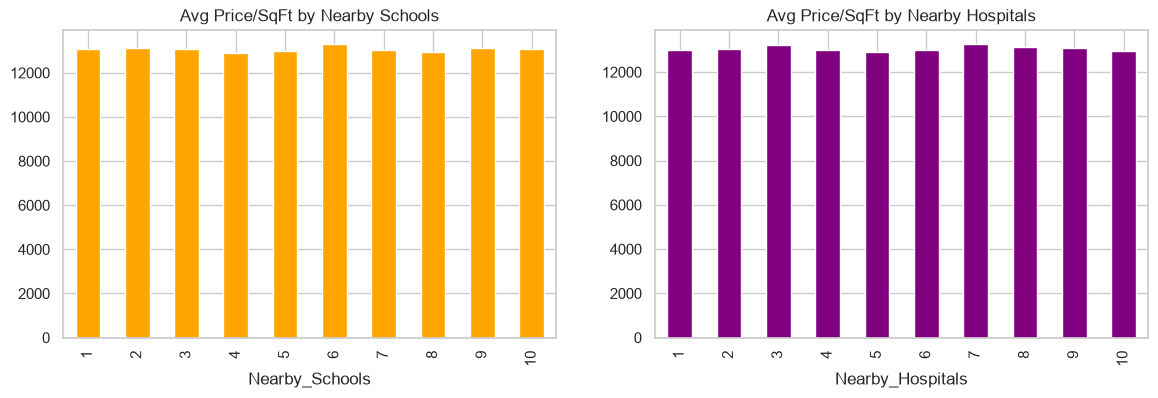

Schools corr  : -0.0
Hospitals corr: -0.0


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("Nearby_Schools")["PPSF"].mean().plot(kind="bar", ax=ax[0], color="orange")
ax[0].set_title("Avg Price/SqFt by Nearby Schools")
df.groupby("Nearby_Hospitals")["PPSF"].mean().plot(kind="bar", ax=ax[1], color="purple")
ax[1].set_title("Avg Price/SqFt by Nearby Hospitals")
plt.show()
print("Schools corr  :", df["Nearby_Schools"].corr(df["PPSF"]).round(3))
print("Hospitals corr:", df["Nearby_Hospitals"].corr(df["PPSF"]).round(3))

# Cell 14: Q14, price by furnished status

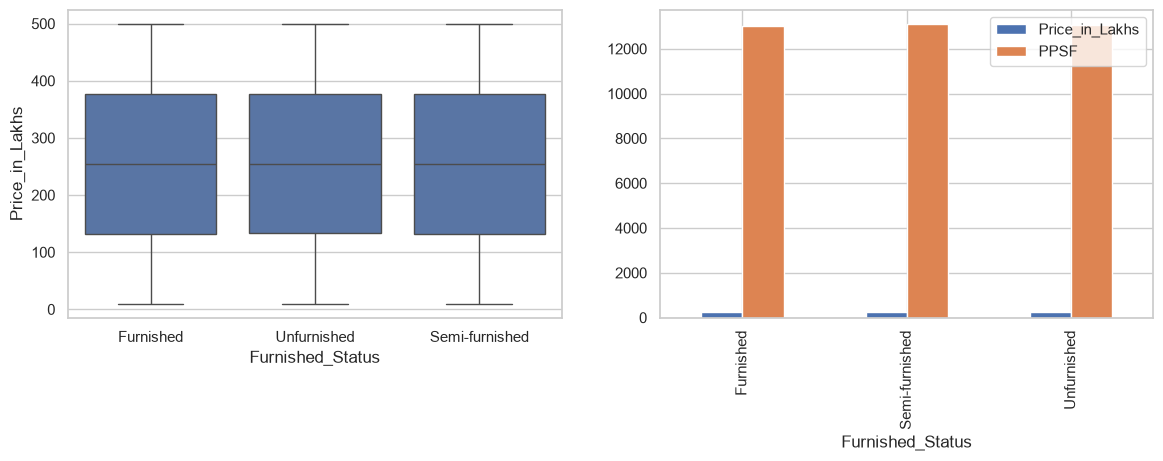

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", ax=ax[0])
df.groupby("Furnished_Status")[["Price_in_Lakhs","PPSF"]].mean().round(1).plot(kind="bar", ax=ax[1])
plt.show()

# Cell 15: Q15, price per sqft by facing

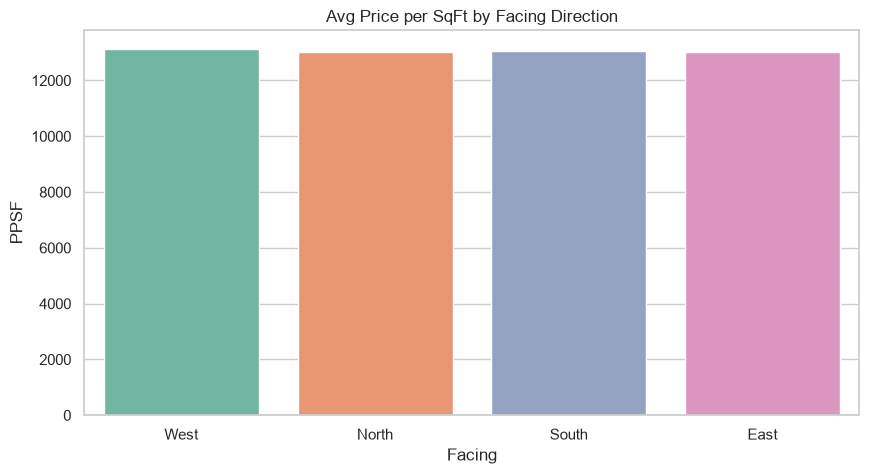

In [19]:
sns.barplot(data=df, x="Facing", y="PPSF", estimator="mean", errorbar=None, palette="Set2")
plt.title("Avg Price per SqFt by Facing Direction"); plt.show()

# Cell 16: Q16 and Q17, owner type and availability counts

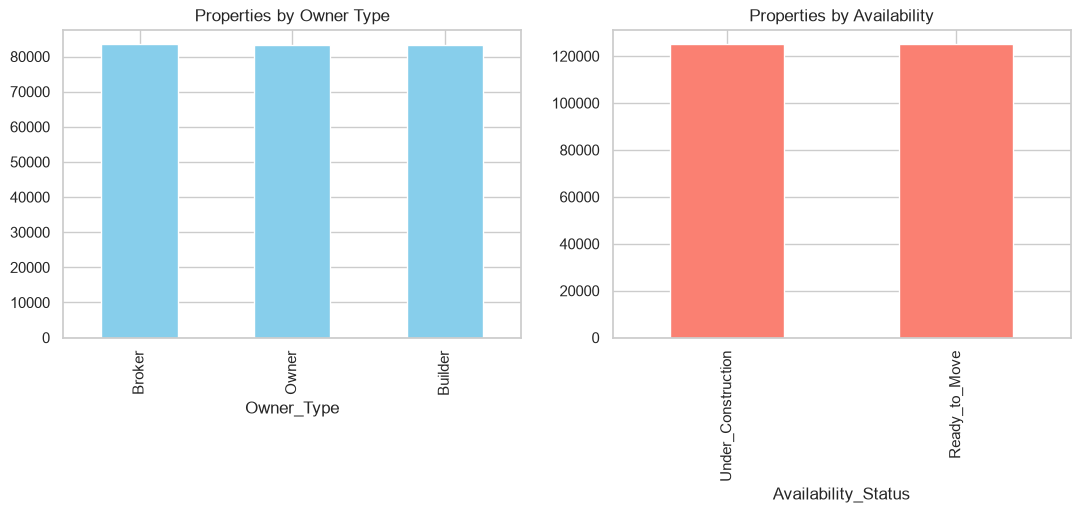

Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64 
 Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["Owner_Type"].value_counts().plot(kind="bar", ax=ax[0], color="skyblue", title="Properties by Owner Type")
df["Availability_Status"].value_counts().plot(kind="bar", ax=ax[1], color="salmon", title="Properties by Availability")
plt.show()
print(df["Owner_Type"].value_counts(), "\n", df["Availability_Status"].value_counts())

# Cell 17: Q18, parking space vs price

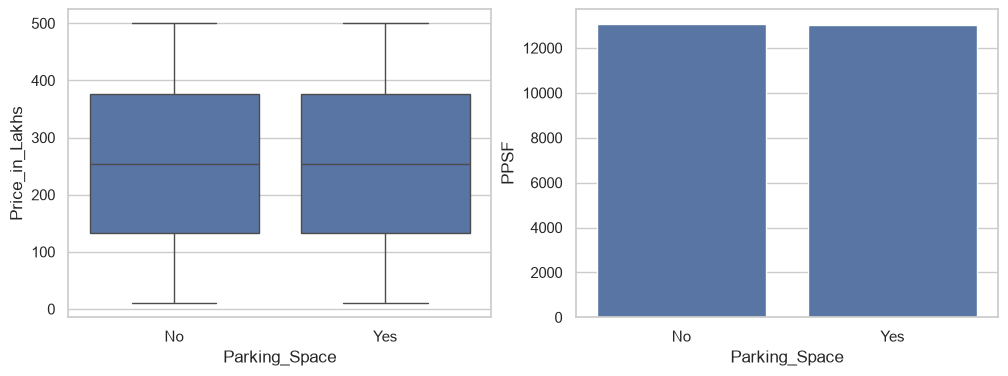

               Price_in_Lakhs     PPSF
Parking_Space                         
No                      254.4  13071.8
Yes                     254.7  13044.7


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Parking_Space", y="Price_in_Lakhs", ax=ax[0])
sns.barplot(data=df, x="Parking_Space", y="PPSF", errorbar=None, ax=ax[1])
plt.show()
print(df.groupby("Parking_Space")[["Price_in_Lakhs","PPSF"]].mean().round(1))

# Cell 18: Q19, amenities vs price per sqft

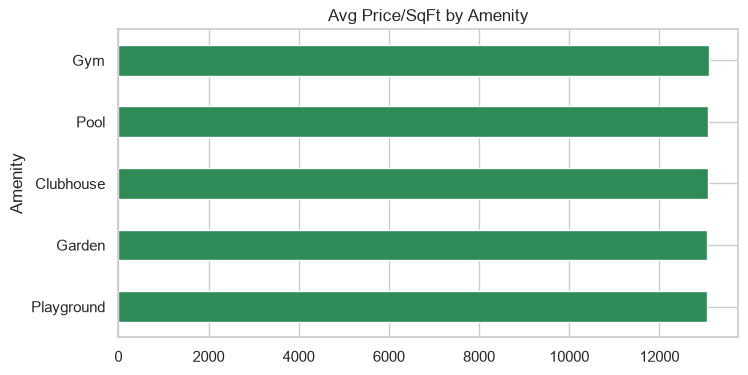

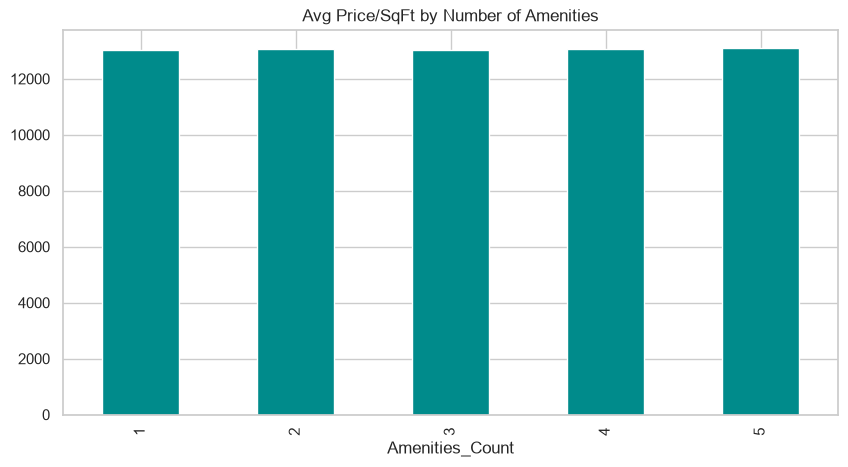

In [22]:
# Each amenity separately
am = df[["Amenities", "PPSF"]].copy()
am["Amenity"] = am["Amenities"].str.split(", ")
am = am.explode("Amenity")
am.groupby("Amenity")["PPSF"].mean().sort_values().plot(kind="barh", color="seagreen", figsize=(8, 4))
plt.title("Avg Price/SqFt by Amenity"); plt.show()

# Number of amenities
df.groupby("Amenities_Count")["PPSF"].mean().plot(kind="bar", color="darkcyan")
plt.title("Avg Price/SqFt by Number of Amenities"); plt.show()

# Cell 19: Q20, public transport vs price per sqft and investment potential

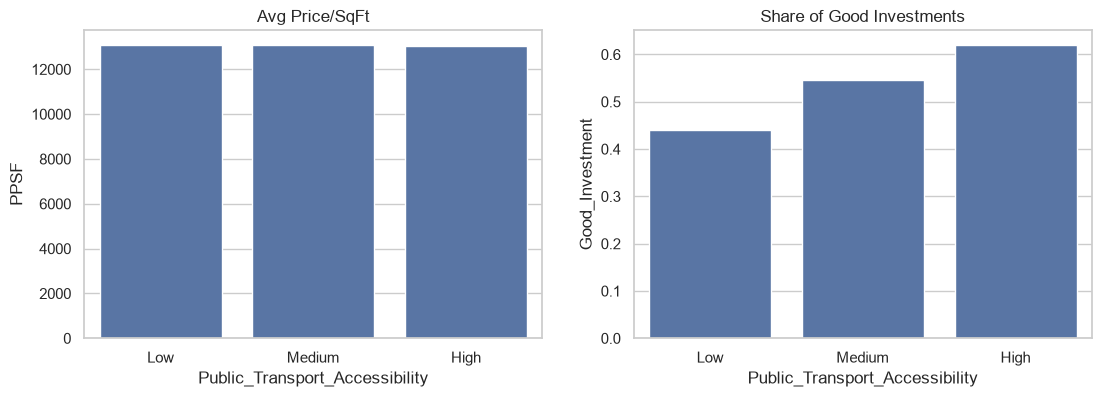

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = ["Low", "Medium", "High"]
sns.barplot(data=df, x="Public_Transport_Accessibility", y="PPSF", order=order, errorbar=None, ax=ax[0])
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Good_Investment", order=order, errorbar=None, ax=ax[1])
ax[0].set_title("Avg Price/SqFt"); ax[1].set_title("Share of Good Investments")
plt.show()

# Cell 20: price trends by city, area vs investment return, crime and infrastructure substitutes

Size vs 5Y return corr: -0.007


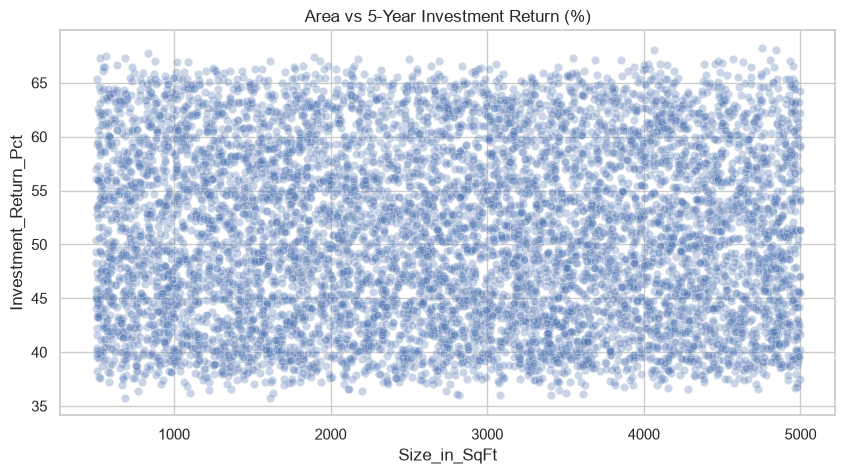

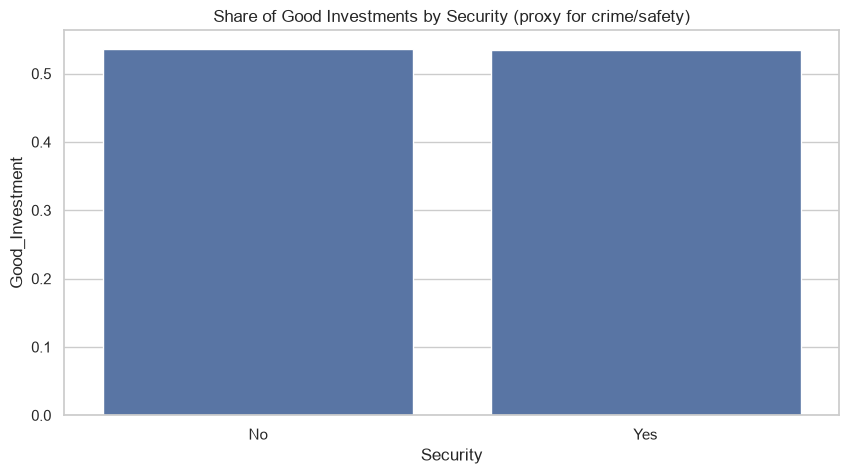

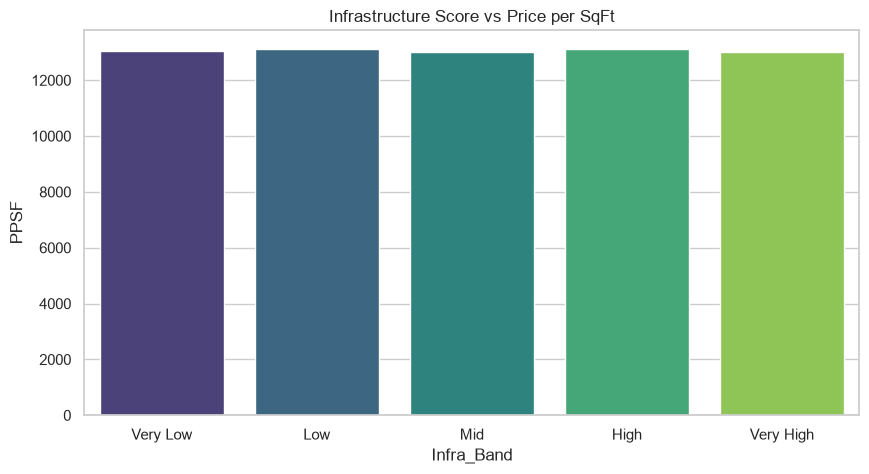

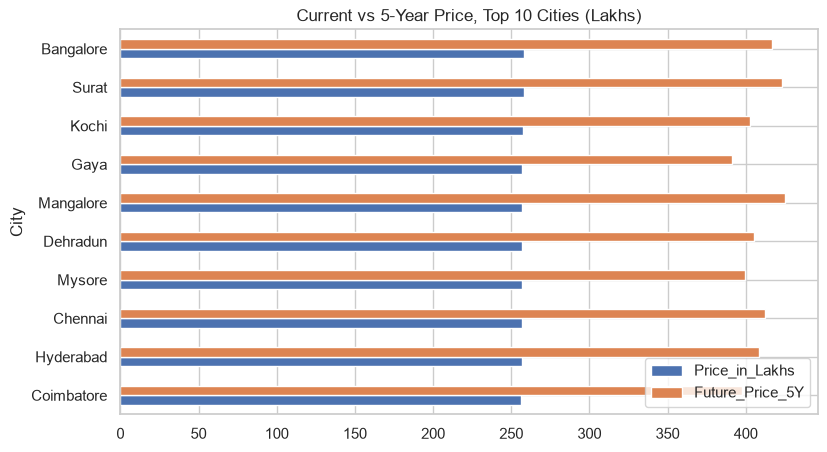

In [24]:
df["Investment_Return_Pct"] = (df["Future_Price_5Y"] / df["Price_in_Lakhs"] - 1) * 100

# (a) Area vs investment return
print("Size vs 5Y return corr:", df["Size_in_SqFt"].corr(df["Investment_Return_Pct"]).round(3))
sns.scatterplot(data=df.sample(8000, random_state=1), x="Size_in_SqFt", y="Investment_Return_Pct", alpha=.3)
plt.title("Area vs 5-Year Investment Return (%)"); plt.show()

# (b) Crime rate is NOT in the dataset; use Security and Infrastructure as the closest safety/quality proxies
sns.barplot(data=df, x="Security", y="Good_Investment", errorbar=None)
plt.title("Share of Good Investments by Security (proxy for crime/safety)"); plt.show()

# (c) Infrastructure score vs resale value (price per sqft)
df["Infra_Band"] = pd.qcut(df["Infrastructure_Score"], 5, labels=["Very Low","Low","Mid","High","Very High"])
sns.barplot(data=df, x="Infra_Band", y="PPSF", errorbar=None, palette="viridis")
plt.title("Infrastructure Score vs Price per SqFt"); plt.show()

# (d) Price trend by city, 5-year projection for the top 10 cities
top_cities = df.groupby("City")["Price_in_Lakhs"].mean().nlargest(10).index
g = df[df["City"].isin(top_cities)].groupby("City")[["Price_in_Lakhs","Future_Price_5Y"]].mean().sort_values("Price_in_Lakhs")
g.plot(kind="barh", figsize=(9, 5)); plt.title("Current vs 5-Year Price, Top 10 Cities (Lakhs)"); plt.show()